In [1]:
# Установка необходимых библиотек для Kaggle (запустите эту ячейку первой)
# Установка необходимых библиотек для Kaggle (обновлённая: добавлен mapclassify для geopandas.explore())
!pip install pystac-client folium stackstac xarray-spatial geopandas mapclassify -q
!pip install -q rioxarray

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.3/64.3 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 30.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 882.2/882.2 kB 32.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 74.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.7/207.7 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.2/22.2 MB 75.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 91.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
category-encoders 2.7.0 requires scikit-learn<1.6.0,>=1.0.0, but you have scikit-learn 1.7.2 which is incompatible.
cesium 0.12.4 requires numpy<3.0,>=2.0, but you have numpy 1.26.4 which is incom

In [2]:
# Импорт библиотек
import pystac_client
import folium
from folium import plugins  # Для плагинов
# Для чтения данных, анализа и визуализации
import stackstac
import xarray as xr
import geopandas as gpd
import pandas as pd
pd.set_option('display.max_columns', None)
import matplotlib.pyplot as plt
# Отображение графиков в Jupyter
%matplotlib inline

In [3]:
# Доступ к PGC Data Catalog API
cat = pystac_client.Client.open("https://stac.pgc.umn.edu/api/v1/")
print(f"Catalog Title: {cat.title}")
# Просмотр компонентов каталога
cat

Catalog Title: PGC Data Catalog


<Client id=pgc-data-stac>

In [4]:
# Просмотр доступных коллекций в каталоге
for collection in cat.get_collections():
    print(collection)

<CollectionClient id=rema-strips-s2s041-2m>
<CollectionClient id=arcticdem-mosaics-v4.1-2m>
<CollectionClient id=arcticdem-mosaics-v3.0-2m>
<CollectionClient id=arcticdem-mosaics-v3.0-32m>
<CollectionClient id=earthdem-strips-s2s041-2m>
<CollectionClient id=rema-mosaics-v2.0-2m>
<CollectionClient id=arcticdem-mosaics-v4.1-10m>
<CollectionClient id=rema-mosaics-v2.0-32m>
<CollectionClient id=arcticdem-strips-s2s041-2m>
<CollectionClient id=arcticdem-mosaics-v3.0-10m>
<CollectionClient id=rema-mosaics-v2.0-10m>
<CollectionClient id=arcticdem-mosaics-v4.1-32m>


In [5]:
# Фильтрация коллекций для просмотра только ArcticDEM наборов
collection_search = cat.collection_search(q="arcticdem",)
for result in collection_search.collections():
    print(result.id, f"{result.description}", sep="\n")

arcticdem-mosaics-v4.1-2m
ArcticDEM DEM mosaics, version 4.1, 2m resolution
arcticdem-mosaics-v3.0-2m
ArcticDEM DEM mosaics, version 3.0, 2m resolution
arcticdem-mosaics-v3.0-32m
ArcticDEM DEM mosaics, version 3.0, 32m resolution
arcticdem-mosaics-v4.1-10m
ArcticDEM DEM mosaics, version 4.1, 10m resolution
arcticdem-strips-s2s041-2m
ArcticDEM time-stamped strip DEMs, s2s version 4.1, 2m resolution
arcticdem-mosaics-v3.0-10m
ArcticDEM DEM mosaics, version 3.0, 10m resolution
arcticdem-mosaics-v4.1-32m
ArcticDEM DEM mosaics, version 4.1, 32m resolution


/usr/local/lib/python3.11/dist-packages/pystac_client/collection_search.py:306: UserWarning: Server does not conform to COLLECTION_SEARCH. Filtering will be performed client-side where only bbox, datetime, and q arguments are supported
  warnings.warn(


In [6]:
# Получение коллекции ArcticDEM strips
arcticdem_strips_col = cat.get_collection("arcticdem-strips-s2s041-2m")
arcticdem_strips_col

<CollectionClient id=arcticdem-strips-s2s041-2m>

In [7]:
# Получение метаданных коллекции ArcticDEM mosaics v4.1 2m
arcticdem_mosaics_col = cat.get_collection("arcticdem-mosaics-v4.1-2m")
arcticdem_mosaics_col

<CollectionClient id=arcticdem-mosaics-v4.1-2m>

In [8]:
# Создание карты Folium для поиска AOI (области интереса) для пространственного запроса STAC API
# Центр в Санкт-Петербурге
m = folium.Map(
    location=[59.9386, 30.3141],  # (lat, lon)
    zoom_start=11,
    width=1000,
    height=600,
    control_scale=True
)

# Трюк для работы зума колесом мыши в Kaggle/Colab
plugins.ScrollZoomToggler().add_to(m)

# Инструмент для рисования AOI (экспорт в GeoJSON)
plugins.Draw(
    export=True,
    filename='aoi.geojson',
    position='topleft',
    draw_options={
        'polyline': False,
        'marker': False,
        'circlemarker': False,
        'rectangle': True,
        'polygon': True,
        'circle': True
    }
).add_to(m)

# Инструмент для измерений
plugins.MeasureControl(position='bottomleft').add_to(m)

m

In [9]:
# # Масштабируйте и перемещайте карту для выбора bounding box
# # TIP: Запуск запроса на уровне зума по умолчанию (7) вернет МНОГО записей (это нормально, т.к. это только метаданные!)
# # Для более управляемого количества данных для ручного просмотра рекомендуем приблизить к меньшей области
# # В Folium извлекаем границы вида
# bounds = m.get_bounds()  # [[south_lat, west_lon], [north_lat, east_lon]]
# bbox = (bounds[0][1], bounds[0][0], bounds[1][1], bounds[1][0])  # (west, south, east, north)
# bbox

In [10]:
# Альтернатива: ручной ввод bbox после просмотра карты
# 1. Zoom/pan к области на карте выше.
# 2. Наведите мышь на юго-западный угол (southwest) — запишите lon (west), lat (south) из MousePosition.
# 3. Наведите на северо-восточный угол (northeast) — запишите lon (east), lat (north).
# 4. Вставьте значения ниже и запустите.

# Пример для центра СПб (~50x50 км; подкорректируйте по карте)
west = 29.5   # lon_min
south = 59.7  # lat_min
east = 31.0   # lon_max
north = 60.2  # lat_max

bbox = (west, south, east, north)
bbox

(29.5, 59.7, 31.0, 60.2)

In [11]:
# Построение API-запроса для items в bounding box и диапазоне дат
search = cat.search(
    collections=["arcticdem-strips-s2s041-2m"],
    bbox=bbox,
    datetime="2022-01-01/2023-12-31"  # Можно изменить диапазон или удалить для всех данных
)

In [12]:
# Получение items, соответствующих параметрам поиска
items = list(search.items())
len(items)

356

In [13]:
# Загрузка items в geopandas dataframe и просмотр первых пяти записей
# CRS изменен на EPSG:3413 для Arctic
items_gdf = gpd.GeoDataFrame.from_features(search.item_collection().to_dict(), crs="epsg:4326").to_crs(3413)
items_gdf.head(5)

,geometry,gsd,title,created,license,datetime,pgc:rmse,proj:bbox,proj:code,published,pgc:is_lsf,proj:shape,description,instruments,pgc:geocell,end_datetime,pgc:pairname,constellation,pgc:image_ids,pgc:is_xtrack,proj:centroid,proj:geometry,pgc:stripdemid,proj:transform,start_datetime,pgc:s2s_version,pgc:avg_sun_elevs,pgc:setsm_version,pgc:cloud_area_sqkm,pgc:valid_area_sqkm,pgc:water_area_sqkm,pgc:cloud_area_percent,pgc:valid_area_percent,pgc:water_area_percent,pgc:avg_convergence_angle,pgc:masked_matchtag_density,pgc:valid_area_matchtag_density,pgc:avg_expected_height_accuracy
0,"MULTIPOLYGON (((3192937.952 -849813.974, 31928...",2,SETSM_s2s041_W2W3_20231231_10300100F3CE3A00_10...,2024-04-29T00:00:00Z,CC-BY-4.0,2023-12-31T09:46:49Z,1.91370,"[3192834.0, -851136.0, 3199766.0, -838436.0]",EPSG:3413,2024-06-28T00:00:00Z,False,"[6350, 3466]",Digital surface models from photogrammetric el...,"[WV02, WV03]",n60e030,2024-01-07T09:22:30Z,W2W3_20231231_10300100F3CE3A00_104001008FBB9800,maxar,"[10300100F3CE3A00, 104001008FBB9800]",True,"{'lat': 60.14776003826555, 'lon': 30.195189260...","{'type': 'Polygon', 'coordinates': [[[3192834....",W2W3_20231231_10300100F3CE3A00_104001008FBB980...,"[2.0, 0.0, 3192834.0, 0.0, -2.0, -838436.0, 0....",2023-12-31T09:46:49Z,4.1,"[6.85, 7.2]",SETSM 4.3.15,0.068608,56.321410,0.000000,0.001217,0.998783,0.000000,45.890226,0.971820,0.973004,0.835018
1,"MULTIPOLYGON (((3199900.002 -839307.988, 31977...",2,SETSM_s2s041_W2W2_20231231_10300100F3CE3A00_10...,2024-04-29T00:00:00Z,CC-BY-4.0,2023-12-31T09:46:49Z,1.45120,"[3188034, -851032, 3199902, -837100]",EPSG:3413,2024-06-28T00:00:00Z,False,"[6966, 5934]",Digital surface models from photogrammetric el...,"[WV02, WV02]",n60e030,2024-01-03T09:35:53Z,W2W2_20231231_10300100F3CE3A00_10300100F4488D00,maxar,"[10300100F3CE3A00, 10300100F4488D00]",True,"{'lat': 60.16883251174304, 'lon': 30.196927213...","{'type': 'Polygon', 'coordinates': [[[3188034....",W2W2_20231231_10300100F3CE3A00_10300100F4488D0...,"[2.0, 0.0, 3188034.0, 0.0, -2.0, -837100.0, 0....",2023-12-31T09:46:49Z,4.1,"[6.85, 7.0]",SETSM 4.3.15,0.300416,111.790102,0.707008,0.002668,0.992675,0.006278,27.260197,0.981058,0.988298,1.457848
2,"MULTIPOLYGON (((3197230.013 -851012.016, 31886...",2,SETSM_s2s041_W2W2_20231231_10300100F3190E00_10...,2024-04-29T00:00:00Z,CC-BY-4.0,2023-12-31T09:46:49Z,1.37760,"[3188312.0, -851060.0, 3199848.0, -837304.0]",EPSG:3413,2025-04-14T00:00:00Z,False,"[6878, 5768]",Digital surface models from photogrammetric el...,"[WV02, WV02]",n60e030,2024-01-06T09:26:01Z,W2W2_20231231_10300100F3190E00_10300100F3CE3A00,maxar,"[10300100F3190E00, 10300100F3CE3A00]",True,"{'lat': 60.167640629595574, 'lon': 30.19547851...","{'type': 'Polygon', 'coordinates': [[[3188312....",W2W2_20231231_10300100F3190E00_10300100F3CE3A0...,"[2.0, 0.0, 3188312.0, 0.0, -2.0, -837304.0, 0....",2023-12-31T09:46:49Z,4.1,"[7.1, 6.85]",SETSM 4.3.15,1.326208,107.737682,0.286016,0.012159,0.987788,0.002622,27.413182,0.968931,0.980910,1.449391
3,"MULTIPOLYGON (((3197633.965 -851143.980, 31924...",2,SETSM_s2s041_W2W2_20231231_10300100F3062D00_10...,2024-04-29T00:00:00Z,CC-BY-4.0,2023-12-31T09:46:49Z,1.40540,"[3192268.0, -851146.0, 3200086.0, -836558.0]",EPSG:3413,2025-04-14T00:00:00Z,False,"[7294, 3909]",Digital surface models from photogrammetric el...,"[WV02, WV02]",n60e030,2024-01-03T09:36:06Z,W2W2_20231231_10300100F3062D00_10300100F3CE3A00,maxar,"[10300100F3062D00, 10300100F3CE3A00]",True,"{'lat': 60.15084888757254, 'lon': 30.210295572...","{'type': 'Polygon', 'coordinates': [[[3192268....",W2W2_20231231_10300100F3062D00_10300100F3CE3A0...,"[2.0, 0.0, 3192268.0, 0.0, -2.0, -836558.0, 0....",2023-12-31T09:46:49Z,4.1,"[7.0, 6.85]",SETSM 4.3.15,0.000000,68.957264,0.000000,0.000000,1.000000,0.000000,21.208649,0.984667,0.984667,1.888128
4,"MULTIPOLYGON (((3183562.005 -845641.985, 31833...",2,SETSM_s2s041_W2W2_20231231_10300100F1919400_10...,2024-04-29T00:00:00Z,CC-BY-4.0,2023-12-31T09:46:49Z,1.40375,"[3182930.0, -849280.0, 32011

In [14]:
# Запрос geodataframe по атрибутам DEM - хотим intrack DEM strips с менее 0.5% облачности (если применимо; для ArcticDEM может варьироваться)
subset_items_gdf = items_gdf[(items_gdf['pgc:is_xtrack'] == False) & (items_gdf['pgc:cloud_area_percent'] < 0.5)]
len(subset_items_gdf)

9

In [15]:
# Визуализация footprints подмножества geodataframe
subset_items_gdf.explore(tooltip=["pgc:pairname", "start_datetime", "pgc:cloud_area_percent", "pgc:water_area_percent", "pgc:valid_area_percent"])

In [16]:
# Построение поискового запроса для коллекции mosaics v4.1 2m и bbox
mosaic_search = cat.search(
    collections=["arcticdem-mosaics-v4.1-2m"],
    bbox=bbox
)
# Получение списка items
mosaic_items = list(mosaic_search.items())
len(mosaic_items)
# Преобразование items в geodataframe
mosaic_items_gdf = gpd.GeoDataFrame.from_features(mosaic_search.item_collection().to_dict(), crs="epsg:4326").to_crs(3413)
mosaic_items_gdf

,geometry,gsd,title,created,license,datetime,pgc:tile,proj:bbox,proj:code,published,proj:shape,description,end_datetime,constellation,pgc:data_perc,pgc:supertile,proj:centroid,proj:geometry,proj:transform,start_datetime,pgc:pairname_ids,pgc:num_components,pgc:release_version
0,"MULTIPOLYGON (((3249899.957 -799899.998, 33000...",2,32_73_2_2_2m_v4.1,2023-06-02T00:00:00Z,CC-BY-4.0,2011-04-05T00:00:00Z,32_73_2_2,"[3249900, -850100, 3300100, -799900]",EPSG:3413,2023-07-19T00:00:00Z,"[25100, 25100]",Digital surface model mosaic from photogrammet...,2021-09-06T00:00:00Z,maxar,0.989308,32_73,"{'lat': 59.5328672672588, 'lon': 30.8608916883...","{'type': 'Polygon', 'coordinates': [[[3249900....","[2.0, 0.0, 3249900.0, 0.0, -2.0, -799900.0, 0....",2011-04-05T00:00:00Z,[GE01_20130904_105041000245D300_1050410002414A...,113,4.1
1,"MULTIPOLYGON (((3149900.039 -799900.016, 32000...",2,32_72_2_2_2m_v4.1,2023-06-02T00:00:00Z,CC-BY-4.0,2010-03-18T00:00:00Z,32_72_2_2,"[3149900, -850100, 3200100, -799900]",EPSG:3413,2023-07-19T00:00:00Z,"[25100, 25100]",Digital surface model mosaic from photogrammet...,2021-08-10T00:00:00Z,maxar,0.927125,32_72,"{'lat': 60.36925267810972, 'lon': 30.434235753...","{'type': 'Polygon', 'coordinates': [[[3149900....","[2.0, 0.0, 3149900.0, 0.0, -2.0, -799900.0, 0....",2010-03-18T00:00:00Z,[GE01_20130713_10504100025A3E00_10504100025F80...,137,4.1
2,"MULTIPOLYGON (((3149899.967 -849899.982, 32001...",2,32_72_1_2_2m_v4.1,2023-06-02T00:00:00Z,CC-BY-4.0,2009-10-06T00:00:00Z,32_72_1_2,"[3149900, -900100, 3200100, -849900]",EPSG:3413,2023-07-19T00:00:00Z,"[25100, 25100]",Digital surface model mosaic from photogrammet...,2021-08-10T00:00:00Z,maxar,0.709733,32_72,"{'lat': 60.25744126938911, 'lon': 29.592296359...","{'type': 'Polygon', 'coordinates': [[[3149900....","[2.0, 0.0, 3149900.0, 0.0, -2.0, -849900.0, 0....",2009-10-06T00:00:00Z,[GE01_20130514_1050410002516F00_105041000248C1...,144,4.1
3,"MULTIPOLYGON (((3199899.957 -749899.978, 32500...",2,33_73_1_1_2m_v4.1,2023-06-02T00:00:00Z,CC-BY-4.0,2009-05-20T00:00:00Z,33_73_1_1,"[3199900, -800100, 3250100, -749900]",EPSG:3413,2023-07-19T00:00:00Z,"[25100, 25100]",Digital surface model mosaic from photogrammet...,2021-09-06T00:00:00Z,maxar,0.497212,33_73,"{'lat': 60.054814756890025, 'lon': 31.48746936...","{'type': 'Polygon', 'coordinates': [[[3199900....","[2.0, 0.0, 3199900.0, 0.0, -2.0, -749900.0, 0....",2009-05-20T00:00:00Z,[W1W1_20090520_1020010007119D00_10200100073C7F...,41,4.1
4,"MULTIPOLYGON (((3199899.965 -799900.018, 32501...",2,32_73_2_1_2m_v4.1,2023-06-02T00:00:00Z,CC-BY-4.0,2007-11-05T00:00:00Z,32_73_2_1,"[3199900, -850100, 3250100, -799900]",EPSG:3413,2023-07-19T00:00:00Z,"[25100, 25100]",Digital surface model mosaic from photogrammet...,2021-08-18T00:00:00Z,maxar,0.957960,32_73,"{'lat': 59.95086353928564, 'lon': 30.650667957...","{'type': 'Polygon', 'coordinates': [[[3199900....","[2.0, 0.0, 3199900.0, 0.0, -2.0, -799900.0, 0....",2007-11-05T00:00:00Z,[GE01_20110227_1050410002BD8200_1050410002BB85...,346,4.1
5,"MULTIPOLYGON (((3199900.035 -849900.026, 32500...",2,32_73_1_1_2m_v4.1,2023-06-02T00:00:00Z,CC-BY-4.0,2007-11-05T00:00:00Z,32_73_1_1,"[3199900, -900100, 3250100, -849900]",EPSG:3413,2023-07-19T00:00:00Z,"[25100, 25100]",Digital surface model mosaic from photogrammet...,2021-10-04T00:00:00Z,maxar,0.737736,32_73,"{'lat': 59.84087892659674, 'lon': 29.820072565...","{'type': 'Polygon', 'coordinates': [[[3199900....","[2.0, 0.0, 3199900.0, 0.0, -2.0, -849900.0, 0....",2007-11-05T00:00:00Z,[GE01_20110227_1050410002BD8200_1050410002BB85...,261,4.1


In [17]:
#visualize tile extents

mosaic_items_gdf.explore(tooltip=["pgc:tile"])

In [18]:
# Загрузка и визуализация mosaics
mosaic_stack = stackstac.stack(mosaic_items[5], epsg=3413)  # Или используйте subset_mosaic_items[0] если подмножество
mosaic_stack

<xarray.DataArray 'stackstac-c553761cc3f90338bd2a6f81c2b79cf2' (time: 1,
                                                                band: 7,
                                                                y: 25101,
                                                                x: 25101)> Size: 35GB
dask.array<fetch_raster_window, shape=(1, 7, 25101, 25101), dtype=float64, chunksize=(1, 1, 1024, 1024), chunktype=numpy.ndarray>
Coordinates: (12/31)
  * time                 (time) datetime64[ns] 8B 2007-11-05
    id                   (time) <U17 68B '32_73_1_1_2m_v4.1'
  * band                 (band) <U9 252B 'dem' 'mad' ... 'datamask' 'hillshade'
  * x                    (x) float64 201kB 3.187e+06 3.187e+06 ... 3.263e+06
  * y                    (y) float64 201kB -8.376e+05 -8.376e+05 ... -9.132e+05
    description          <U187 748B 'Digital surface model mosaic from photog...
    ...                   ...
    proj:centroid        (band) object 56B None ... {'lat': 59.84087892659674...
    alternate            (band) object 56B {'s3': {'href': 's3://pgc-opendata...
    unit                 (band) object 56B 'meter' 'meter' None ... None None
    data_type            (band) <U7 196B 'float32' 'float32' ... 'uint8' 'uint8'
    nodata               (band) int64 56B -9999 -9999 0 0 0 0 0
    epsg                 int64 8B 3413
Attributes:
    spec:           RasterSpec(epsg=3413, bounds=(3187151.6644901065, -913195...
    crs:            epsg:3413
    transform:      | 3.01, 0.00, 3187151.66|\n| 0.00,-3.01,-837618.69|\n| 0....
    resolution_xy:  (3.0108086045231834, 3.0109049063050737)

In [19]:
# Построение поискового запроса для коллекции mosaics v4.1 2m и bbox
mosaic_search = cat.search(
    collections=["arcticdem-mosaics-v4.1-32m"],
    bbox=bbox
)
# Получение списка items
mosaic_items = list(mosaic_search.items())
len(mosaic_items)
# Преобразование items в geodataframe
mosaic_items_gdf = gpd.GeoDataFrame.from_features(mosaic_search.item_collection().to_dict(), crs="epsg:4326").to_crs(3413)
mosaic_items_gdf

,geometry,gsd,title,created,license,datetime,pgc:tile,proj:bbox,proj:code,published,proj:shape,description,end_datetime,constellation,pgc:data_perc,pgc:supertile,proj:centroid,proj:geometry,proj:transform,start_datetime,pgc:pairname_ids,pgc:num_components,pgc:release_version
0,"MULTIPOLYGON (((3099903.959 -799904.000, 32000...",32,32_72_32m_v4.1,2023-06-26T00:00:00Z,CC-BY-4.0,2009-10-06T00:00:00Z,32_72,"[3099904, -900096, 3200096, -799904]",EPSG:3413,2023-07-19T00:00:00Z,"[3131, 3131]",Digital surface model mosaic from photogrammet...,2021-09-17T00:00:00Z,maxar,0.804936,32_72,"{'lat': 60.52297954095619, 'lon': 29.898901838...","{'type': 'Polygon', 'coordinates': [[[3099904....","[32.0, 0.0, 3099904.0, 0.0, -32.0, -799904.0, ...",2009-10-06T00:00:00Z,[GE01_20130514_1050410002516F00_105041000248C1...,245,4.1
1,"MULTIPOLYGON (((3199903.956 -699904.009, 33000...",32,33_73_32m_v4.1,2023-06-26T00:00:00Z,CC-BY-4.0,2009-05-20T00:00:00Z,33_73,"[3199904, -800096, 3300096, -699904]",EPSG:3413,2023-07-19T00:00:00Z,"[3131, 3131]",Digital surface model mosaic from photogrammet...,2021-10-07T00:00:00Z,maxar,0.724660,33_73,"{'lat': 59.89419448605489, 'lon': 32.005383208...","{'type': 'Polygon', 'coordinates': [[[3199904....","[32.0, 0.0, 3199904.0, 0.0, -32.0, -699904.0, ...",2009-05-20T00:00:00Z,[GE01_20130912_1050410003F6B100_1050410003E921...,80,4.1
2,"MULTIPOLYGON (((3199903.981 -799903.989, 33000...",32,32_73_32m_v4.1,2023-06-26T00:00:00Z,CC-BY-4.0,2007-11-05T00:00:00Z,32_73,"[3199904, -900096, 3300096, -799904]",EPSG:3413,2023-07-19T00:00:00Z,"[3131, 3131]",Digital surface model mosaic from photogrammet...,2021-10-04T00:00:00Z,maxar,0.918870,32_73,"{'lat': 59.688013828440766, 'lon': 30.34324888...","{'type': 'Polygon', 'coordinates': [[[3199904....","[32.0, 0.0, 3199904.0, 0.0, -32.0, -799904.0, ...",2007-11-05T00:00:00Z,[GE01_20110227_1050410002BD8200_1050410002BB85...,426,4.1


In [20]:

mosaic_items_gdf.explore(tooltip=["pgc:tile"])

In [21]:
# Загрузка и визуализация mosaics
mosaic_stack = stackstac.stack(mosaic_items[2], epsg=3413)  # Или используйте subset_mosaic_items[0] если подмножество
mosaic_stack

<xarray.DataArray 'stackstac-73fb3dc34d395dc8c324ddfe9c077635' (time: 1,
                                                                band: 7,
                                                                y: 3132, x: 3132)> Size: 549MB
dask.array<fetch_raster_window, shape=(1, 7, 3132, 3132), dtype=float64, chunksize=(1, 1, 1024, 1024), chunktype=numpy.ndarray>
Coordinates: (12/31)
  * time                 (time) datetime64[ns] 8B 2007-11-05
    id                   (time) <U14 56B '32_73_32m_v4.1'
  * band                 (band) <U9 252B 'dem' 'mad' ... 'datamask' 'hillshade'
  * x                    (x) float64 25kB 3.175e+06 3.175e+06 ... 3.324e+06
  * y                    (y) float64 25kB -7.77e+05 -7.77e+05 ... -9.262e+05
    description          <U187 748B 'Digital surface model mosaic from photog...
    ...                   ...
    proj:centroid        object 8B {'lat': 59.688013828440766, 'lon': 30.3432...
    alternate            (band) object 56B {'s3': {'href': 's3://pgc-opendata...
    unit                 (band) object 56B 'meter' 'meter' None ... None None
    data_type            (band) <U7 196B 'float32' 'float32' ... 'uint8' 'uint8'
    nodata               (band) int64 56B -9999 -9999 0 0 0 0 0
    epsg                 int64 8B 3413
Attributes:
    spec:           RasterSpec(epsg=3413, bounds=(3175128.4359256746, -926279...
    crs:            epsg:3413
    transform:      | 47.66, 0.00, 3175128.44|\n| 0.00,-47.67,-776976.55|\n| ...
    resolution_xy:  (47.66386603506229, 47.67019754515928)

/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


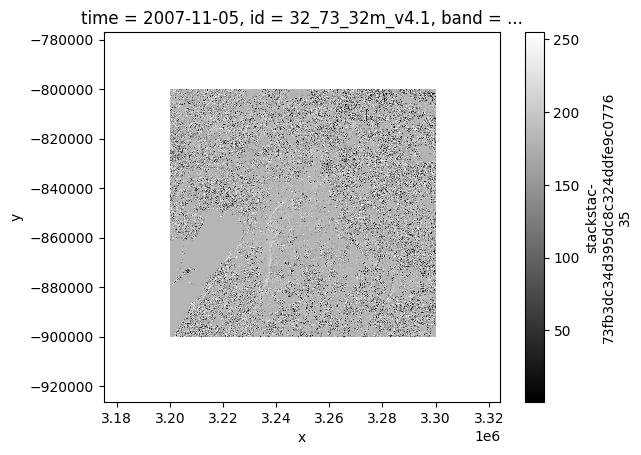

In [22]:
mosaic_stack.sel(band='hillshade').plot(cmap='gist_gray')

CPU times: user 4.27 s, sys: 360 ms, total: 4.63 s
Wall time: 4.43 s


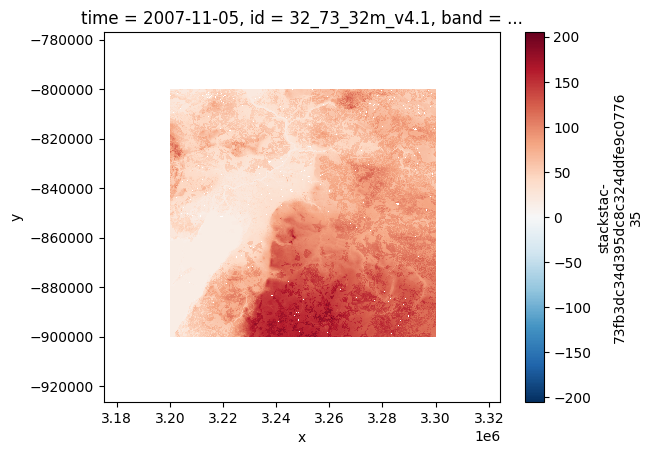

In [23]:
%%time

mosaic_stack.sel(band='dem').plot()

In [24]:
import os
import pystac_client
import rioxarray

# 1. Настройки доступа
os.environ['AWS_NO_SIGN_REQUEST'] = 'YES'
os.environ['AWS_REGION'] = 'us-west-2'

# 2. Правильные параметры
# Коллекция для мозаик (Mosaic) версии 4.1
COLLECTION_ID = "arcticdem-mosaics-v4.1-2m"

# Полные ID из вашей таблицы (Tile + Resolution + Version)
# Мы формируем их автоматически из коротких имен
short_ids = ["32_73_1_1", "32_73_2_1"]
full_ids = [f"{tid}_2m_v4.1" for tid in short_ids]

OUTPUT_DIR = "/kaggle/working/"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print(f"🔍 Поиск тайлов в коллекции {COLLECTION_ID}...")
print(f"📋 Целевые ID: {full_ids}")

# 3. Поиск
api = pystac_client.Client.open("https://stac.pgc.umn.edu/api/v1")
search = api.search(
    collections=[COLLECTION_ID],
    ids=full_ids
)
found_items = list(search.items())

if not found_items:
    # Запасной план: если по ID не вышло, ищем по свойству pgc:tile
    print("⚠️ Поиск по ID не дал результатов. Пробуем поиск по свойству pgc:tile...")
    search = api.search(
        collections=[COLLECTION_ID],
        query={"pgc:tile": {"in": short_ids}}
    )
    found_items = list(search.items())

# 4. Скачивание
if not found_items:
    print("❌ Тайлы не найдены. Проверьте, что PGC API доступен и коллекция верна.")
else:
    print(f"✅ Найдено тайлов: {len(found_items)}")
    
    for item in found_items:
        print(f"📥 Загрузка {item.id}...")
        
        # Ссылка на файл (обычно актив 'dem' или 'data')
        asset_key = 'dem' if 'dem' in item.assets else 'data'
        href = item.assets[asset_key].href
        
        try:
            # Ленивая загрузка
            da = rioxarray.open_rasterio(href)
            
            # Сохранение
            save_path = os.path.join(OUTPUT_DIR, f"{item.id}.tif")
            da.rio.to_raster(save_path, compress='LZW')
            
            print(f"💾 Сохранено: {save_path}")
            
        except Exception as e:
            print(f"❌ Ошибка загрузки {item.id}: {e}")

print("🏁 Готово.")

🔍 Поиск тайлов в коллекции arcticdem-mosaics-v4.1-2m...
📋 Целевые ID: ['32_73_1_1_2m_v4.1', '32_73_2_1_2m_v4.1']
✅ Найдено тайлов: 2
📥 Загрузка 32_73_2_1_2m_v4.1...
💾 Сохранено: /kaggle/working/32_73_2_1_2m_v4.1.tif
📥 Загрузка 32_73_1_1_2m_v4.1...
💾 Сохранено: /kaggle/working/32_73_1_1_2m_v4.1.tif
🏁 Готово.


In [25]:
# ======================================================================================
# FLOOD ANALYSIS: MEMORY SAFE MODE (NATIVE GDAL)
# Исправлено: замена subprocess на osgeo.gdal для работы без системных утилит
# ======================================================================================
!pip install -q rioxarray geopandas osmnx folium rasterio mapclassify

import os
import glob
import numpy as np
import geopandas as gpd
import osmnx as ox
import rioxarray
import folium
from rasterio.features import shapes
from shapely.geometry import box
# Импортируем сам GDAL
from osgeo import gdal 
import warnings

warnings.filterwarnings("ignore")

# Разрешаем GDAL использовать исключения Python (чтобы видеть ошибки)
gdal.UseExceptions()

# ---- Параметры ----
CITY_NAME = "Saint Petersburg, Russia"
FLOOD_LEVEL = 3.05
CRS_METRIC = "EPSG:32636" # UTM Zone 36N
INPUT_DIR = "/kaggle/working/"
VRT_PATH = "temp.vrt"
INTERMEDIATE_FILE = "dem_merged_reprojected.tif"
OUT_FILENAME = "spb_flood_map_final.html"

# Настройки OSMnx
ox.settings.use_cache = True
ox.settings.log_console = False

print(f"📍 Запуск обработки для: {CITY_NAME}")

# --------------------------------------------------------------------------------------
# 1. ОБЪЕДИНЕНИЕ И РЕПРОЕКЦИЯ (ЧЕРЕЗ OSGEO.GDAL)
# --------------------------------------------------------------------------------------
# Ищем файлы
tif_files = glob.glob(os.path.join(INPUT_DIR, "*_2m_v4.1.tif"))
if not tif_files:
    tif_files = glob.glob(os.path.join(INPUT_DIR, "*.tif"))
    # Исключаем промежуточные файлы, чтобы не зациклиться
    tif_files = [f for f in tif_files if "dem_merged" not in f and "temp" not in f]

if not tif_files:
    raise FileNotFoundError("❌ Файлы .tif не найдены в /kaggle/working/!")

print(f"   Найдено файлов: {len(tif_files)}")

try:
    # 1.1 Создаем виртуальную мозаику (VRT)
    # Это создает "легкий" файл-описание, не загружая данные в RAM
    print("🔄 Создание виртуальной мозаики (gdal.BuildVRT)...")
    vrt_options = gdal.BuildVRTOptions(resampleAlg='bilinear')
    ds = gdal.BuildVRT(VRT_PATH, tif_files, options=vrt_options)
    ds.FlushCache() # Сохраняем на диск
    ds = None # Закрываем файл
    
    # 1.2 Репроекция (Warp)
    print(f"🔄 Репроекция и сохранение (gdal.Warp)...")
    # Понижаем разрешение до 5 метров для оптимизации памяти и скорости карты
    TARGET_RES = 5 
    
    warp_options = gdal.WarpOptions(
        format="GTiff",
        dstSRS=CRS_METRIC,
        xRes=TARGET_RES, 
        yRes=TARGET_RES,
        dstNodata=-9999,
        resampleAlg="bilinear",
        creationOptions=["COMPRESS=LZW", "TILED=YES"] # Сжатие и тайлинг
    )
    
    # Эта операция выполняется на C++ уровне GDAL, экономя память Python
    ds = gdal.Warp(INTERMEDIATE_FILE, VRT_PATH, options=warp_options)
    ds = None # Закрываем и сохраняем файл
    
    print("✅ DEM успешно обработан и сохранен на диске.")

except Exception as e:
    print(f"❌ Критическая ошибка GDAL: {e}")
    raise e

# --------------------------------------------------------------------------------------
# 2. АНАЛИЗ (PYTHON)
# --------------------------------------------------------------------------------------
print("📥 Загрузка обработанного рельефа...")
# Открываем готовый файл через rioxarray
dem = rioxarray.open_rasterio(INTERMEDIATE_FILE, masked=True)

# 2.1 Калибровка
print("⚖️ Калибровка высот...")
flat_vals = dem.values.flatten()
valid_vals = flat_vals[~np.isnan(flat_vals)]
# Фильтр от артефактов
valid_vals = valid_vals[(valid_vals > -50) & (valid_vals < 50)]

water_offset = 0
if len(valid_vals) > 0:
    # Ищем уровень воды (2-й перцентиль)
    water_base = np.percentile(valid_vals, 2)
    print(f"   Базовый уровень (вода): {water_base:.2f} м")
    if abs(water_base) > 0.5:
        water_offset = water_base
        print(f"   Поправка к уровню наводнения: {-water_offset:.2f} м")

# 2.2 Расчет маски
print(f"🌊 Расчет зоны затопления (> {FLOOD_LEVEL} м)...")
# Учитываем поправку в пороге отсечения, а не вычитаем из массива (экономия RAM)
effective_flood_level = FLOOD_LEVEL + water_offset
flood_mask = dem <= effective_flood_level
flood_mask = flood_mask.astype('uint8')

# 2.3 Векторизация
print("📐 Векторизация...")
mask_arr = flood_mask.values[0]
transform = dem.rio.transform()

results = (
    {'properties': {'val': v}, 'geometry': s}
    for i, (s, v) in enumerate(shapes(mask_arr, mask=mask_arr==1, transform=transform))
)
geoms = list(results)

if not geoms:
    print("🎉 Затопления не обнаружено.")
else:
    flood_poly = gpd.GeoDataFrame.from_features(geoms, crs=CRS_METRIC)
    flood_poly = flood_poly.dissolve()
    print(f"   Площадь затопления: {flood_poly.geometry.area.sum() / 10000:.2f} га")

    # ----------------------------------------------------------------------------------
    # 3. OSM И КАРТА
    # ----------------------------------------------------------------------------------
    print("🏗️ Загрузка данных OSM...")
    xmin, ymin, xmax, ymax = dem.rio.bounds()
    # Конвертируем bbox в Lat/Lon
    bbox_poly = gpd.GeoDataFrame({'geometry': [box(xmin, ymin, xmax, ymax)]}, crs=CRS_METRIC).to_crs("EPSG:4326")
    b_minx, b_miny, b_maxx, b_maxy = bbox_poly.total_bounds
    
    try:
        landuse = ox.features_from_bbox(bbox=[b_miny, b_maxy, b_minx, b_maxx], tags={'landuse': True})
        
        if not landuse.empty:
            landuse = landuse.to_crs(CRS_METRIC)
            landuse = landuse[landuse.geometry.type.isin(['Polygon', 'MultiPolygon'])]
            
            print("💥 Анализ ущерба...")
            impact = gpd.overlay(landuse, flood_poly, how='intersection')
            impact['flooded_ha'] = impact.geometry.area / 10000
            
            print("\n📊 === ТОП ПОСТРАДАВШИХ ЗОН ===")
            print(impact.groupby('landuse')['flooded_ha'].sum().sort_values(ascending=False).head(10))
            
            # ВИЗУАЛИЗАЦИЯ
            print("\n🗺️ Генерация карты...")
            cy, cx = (b_miny + b_maxy)/2, (b_minx + b_maxx)/2
            m = folium.Map(location=[cy, cx], zoom_start=12, tiles='CartoDB positron')

            # Упрощение геометрии для Folium (15м точность)
            simple_flood = flood_poly.to_crs("EPSG:4326")
            simple_flood.geometry = simple_flood.geometry.simplify(15)
            
            folium.GeoJson(
                simple_flood, name='Вода',
                style_function=lambda x: {'fillColor': '#00BFFF', 'color': 'none', 'fillOpacity': 0.6}
            ).add_to(m)
            
            if not impact.empty:
                simple_impact = impact.to_crs("EPSG:4326")
                simple_impact.geometry = simple_impact.geometry.simplify(15)
                
                folium.GeoJson(
                    simple_impact, name='Объекты',
                    style_function=lambda x: {'fillColor': '#FF4500', 'color': 'black', 'weight': 0.5, 'fillOpacity': 0.5},
                    tooltip=folium.GeoJsonTooltip(fields=['landuse', 'flooded_ha'], aliases=['Тип', 'Га'], localize=True)
                ).add_to(m)

            folium.LayerControl().add_to(m)
            m.save(OUT_FILENAME)
            print(f"✅ Карта сохранена: {OUT_FILENAME}")
            
    except Exception as e:
        print(f"⚠️ Ошибка при работе с OSM или картой: {e}")

# Очистка
if os.path.exists(VRT_PATH): os.remove(VRT_PATH)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 101.5/101.5 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 338.4/338.4 kB 9.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.12.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
bigframes 2.12.0 requires rich<14,>=12.4.4, but you have rich 14.2.0 which is incompatible.
📍 Запуск обработки для: Saint Petersburg, Russia
   Найдено файлов: 2
🔄 Создание виртуальной мозаики (gdal.BuildVRT)...
🔄 Репроекция и сохранение (gdal.Warp)...
✅ DEM успешно обработан и сохранен на диске.
📥 Загрузка обработанного рельефа...
⚖️ Калибровка высот...
   Базовый уровень (вода): 15.52 м
   Поправка к уровню наводнения: -15.52 м
🌊 Расчет зоны затопления (> 3.05 м)...
📐 Векторизация...
   Площадь затопления: 68440.85 га
🏗️ Загрузка данных OSM...
